# 04.02 — Soluciones de Tychonoff

## 04.02.0 — Orden de esta colección

Este es el **Notebook 02** de la secuencia de las notas.

Su correspondencia con el temario oficial es

$$
\boxed{\text{Tema oficial 4.8: no unicidad del problema global de Cauchy}}
$$

Aunque el número oficial es

$$
4.8,
$$

este notebook ocupa el segundo lugar porque así aparece en las notas, inmediatamente después del núcleo fundamental.


## 04.02.1 — Transcripción literal normalizada

### **Problema de Tychonoff**

En las notas aparece

$$
\begin{cases}
u_t=u_{xx},
&
(x,t)\in\mathbb R\times\mathbb R^+,
\\[2mm]
u(x,0)=0,
&
x\in\mathbb R.
\end{cases}
$$

También se señala que

$$
u(x,t)=0
$$

es la solución trivial.


## 04.02.2 — Función plana

### **Definición 04.02.1 — Función plana en el origen**

Sea

$$
f\in C^\infty([0,\infty)).
$$

Diremos que

$$
f
$$

es **plana en el origen** si

$$
f^{(m)}(0)=0
$$

para todo entero

$$
m\geq0.
$$

---

### **Ejemplo 04.02.2 — Exponencial plana**

Definimos

$$
f(t)
=
\begin{cases}
e^{-1/t^2},
&
t>0,
\\[2mm]
0,
&
t\leq0.
\end{cases}
$$

Entonces

$$
f\in C^\infty(\mathbb R)
$$

y

$$
f^{(m)}(0)=0
$$

para todo

$$
m\geq0.
$$


## 04.02.3 — Serie de Tychonoff

### **Proposición 04.02.3 — Identidad formal**

Supongamos que las series relevantes convergen localmente de manera uniforme.

Definimos

$$
u(x,t)
=
\sum_{k=0}^{\infty}
\frac{f^{(k)}(t)}{(2k)!}x^{2k}.
$$

Entonces

$$
u_t
=
\sum_{k=0}^{\infty}
\frac{f^{(k+1)}(t)}{(2k)!}x^{2k},
$$

mientras que

$$
u_{xx}
=
\sum_{k=1}^{\infty}
\frac{f^{(k)}(t)}{(2k-2)!}x^{2k-2}.
$$

Con el cambio

$$
j=k-1,
$$

obtenemos

$$
u_{xx}
=
\sum_{j=0}^{\infty}
\frac{f^{(j+1)}(t)}{(2j)!}x^{2j}
=
u_t.
$$


## 04.02.4 — No unicidad

### **Teorema 04.02.4 — Ejemplo de Tychonoff**

Sea

$$
f(t)
=
\begin{cases}
e^{-1/t^2},
&
t>0,
\\[2mm]
0,
&
t\leq0.
\end{cases}
$$

La serie

$$
u(x,t)
=
\sum_{k=0}^{\infty}
\frac{f^{(k)}(t)}{(2k)!}x^{2k}
$$

define una solución clásica no trivial de

$$
u_t-u_{xx}=0
$$

con dato inicial

$$
u(x,0)=0.
$$

Además,

$$
u(0,t)=f(t)>0
$$

para

$$
t>0.
$$

Por tanto, sin imponer una condición de crecimiento espacial, el problema global de Cauchy no es único.

---

### **Observación 04.02.5**

Este resultado no contradice los principios del máximo en clases acotadas.

La solución de Tychonoff crece demasiado rápidamente cuando

$$
|x|\longrightarrow\infty.
$$


## 04.02.5 — Simulación estática de sumas truncadas

La suma truncada es

$$
u_N(x,t)
=
\sum_{k=0}^{N}
\frac{f^{(k)}(t)}{(2k)!}x^{2k}.
$$

No es una solución exacta.

Su residuo satisface

$$
\partial_tu_N-\partial_{xx}u_N
=
\frac{f^{(N+1)}(t)}{(2N)!}x^{2N}.
$$


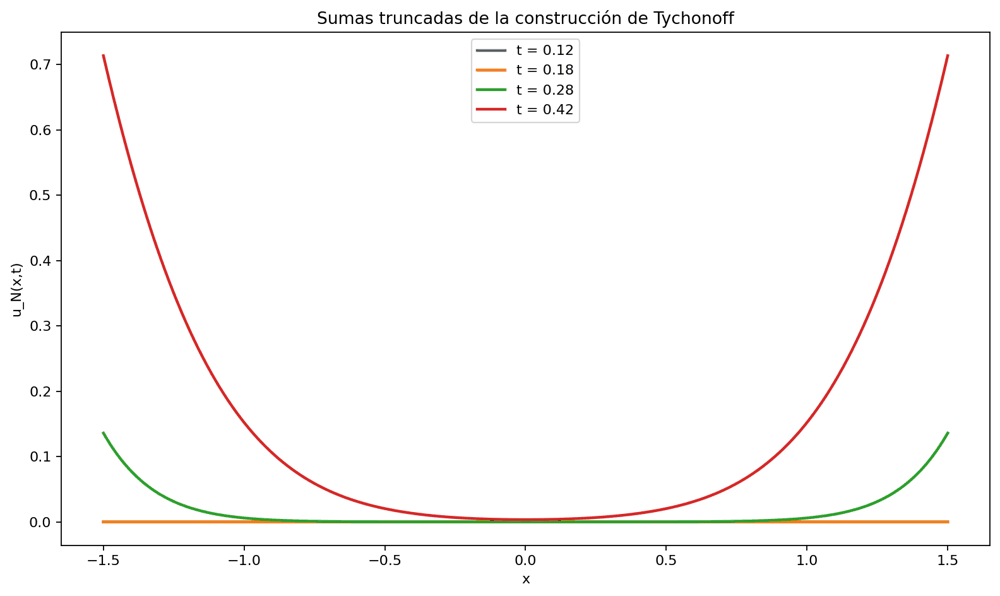

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

def polynomial_derivative(coeffs):
    if len(coeffs) <= 1:
        return np.zeros(1)
    return np.array([j * coeffs[j] for j in range(1, len(coeffs))], dtype=float)

def shift(coeffs, power):
    return np.concatenate([np.zeros(power), coeffs])

def build_polynomials(max_order):
    polys = [np.array([1.0])]
    for _ in range(max_order):
        current = polys[-1]
        a = -shift(polynomial_derivative(current), 2)
        b = 2.0 * shift(current, 3)
        size = max(len(a), len(b))
        nxt = np.zeros(size)
        nxt[:len(a)] += a
        nxt[:len(b)] += b
        polys.append(nxt)
    return polys

N = 7
polys = build_polynomials(N)

def derivative_flat(k, t):
    if t <= 0:
        return 0.0
    z = 1.0 / t
    return np.polynomial.polynomial.polyval(z, polys[k]) * np.exp(-(z**2))

def truncation(x, t):
    value = np.zeros_like(x)
    for k in range(N + 1):
        value += derivative_flat(k, t) * x**(2*k) / math.factorial(2*k)
    return value

x = np.linspace(-1.5, 1.5, 1200)

plt.figure(figsize=(10, 6), dpi=160)
for t in [0.12, 0.18, 0.28, 0.42]:
    plt.plot(x, truncation(x, t), linewidth=2, label=f"t = {t}")

plt.xlabel("x")
plt.ylabel("u_N(x,t)")
plt.title("Sumas truncadas de la construcción de Tychonoff")
plt.legend()
plt.tight_layout()
plt.show()


## 04.02.6 — Animación Manim

Ejecuta la gráfica estática y después la siguiente celda para renderizar y reproducir el MP4 en este cuaderno.

In [ ]:
from pathlib import Path
from runpy import run_path
carpeta = Path.cwd()
if (carpeta / "calor").is_dir():
    carpeta = carpeta / "calor"
# Ejecuta primero la gráfica estática de esta unidad.
renderizar = run_path(str(carpeta / "manim" / "perfiles.py"))["renderizar_perfiles"]

def perfiles(t):
    return [(x, truncation(x, t))]

renderizar("Sumas parciales de Tychonoff", perfiles, (0.16,0.42), [-1.5,1.5,0.5], [-0.086, 0.799, 0.143],
           ['Suma de orden 7'])

## 04.02.7 — Ejercicios de práctica

### **Ejercicio 04.02.1**

Calcule el residuo de

$$
u_N(x,t)
=
\sum_{k=0}^{N}
\frac{f^{(k)}(t)}{(2k)!}x^{2k}.
$$

### **Ejercicio 04.02.2**

Demuestre que

$$
f_\alpha(t)
=
\begin{cases}
e^{-1/t^\alpha},
&
t>0,
\\[2mm]
0,
&
t\leq0,
\end{cases}
$$

es plana en el origen para todo

$$
\alpha>0.
$$



## 04.02.8 — Avance

Se cubrió

$$
\boxed{\text{no unicidad de Tychonoff}}
$$

del tema oficial

$$
4.8.
$$

El siguiente notebook en el orden de las notas es

$$
\boxed{\text{04.03 — Principio débil del máximo}}.
$$
